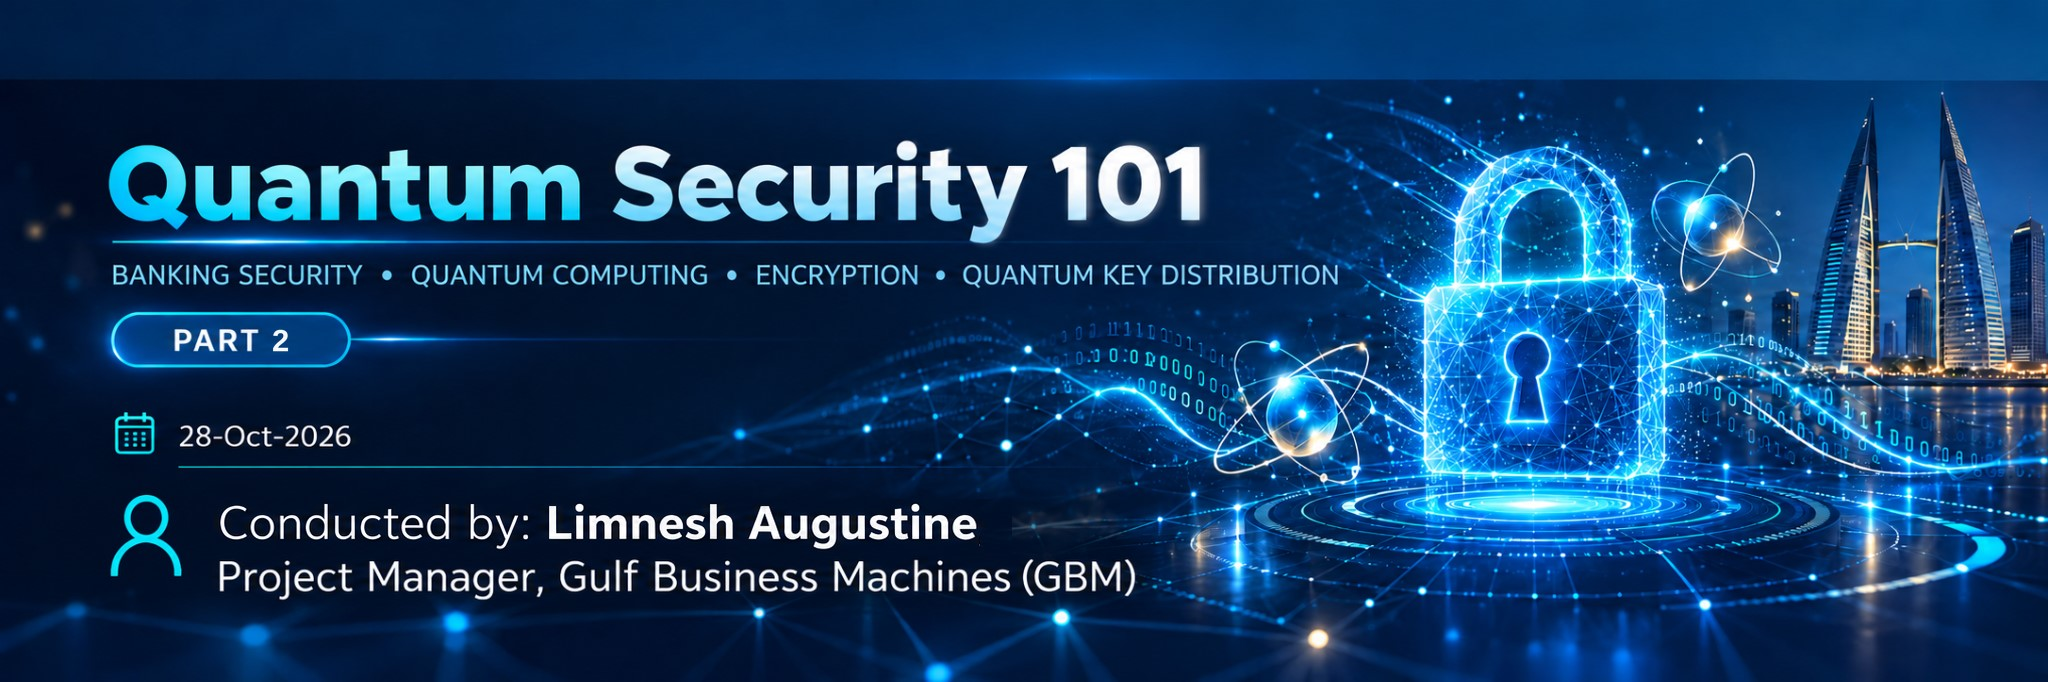
# PART 2 · From Bits to Qubits · The Quantum Threat
**BITEX 2026  /  BAHRAIN SAMPLE BANK (BSB)**

*Understand classical gates, meet the qubit, play with genuine Qiskit circuits, and return to Eve’s saved packet.*

> **Your mission:** Discover why a quantum computer is not just a faster computer and why classical DH/ECDH may be vulnerable in the future.

**🔵 LIVE** = explore in order &nbsp;&nbsp; **🟠 OPTIONAL** = explore afterward  

**How to use:** Read the short explanation, **predict what will happen**, then run the code. Change only values marked **✏️ YOUR TURN**. You do not need to understand every helper function to do the experiments.

---


---
## ⚙️ SETUP — Run once

Runs the Qiskit imports, prepares the interactive Bloch-sphere controls, and defines the reusable teaching/visualization functions. **You do not need to edit the helper code.** The live cells below show the mathematical ideas and short commands.

> The main demonstrations use classical simulations of Qiskit circuits. No real quantum computer is required.


In [ ]:
# @title ⚙️ Setup — run once
# RUN FIRST — Colab setup, imports, shared presentation tools
# Run once; Colab may install Qiskit on a fresh runtime.
# Install Qiskit (if it isn't installed yet)
%pip -q install qiskit pylatexenc ipywidgets cryptography
import sys, subprocess, io, base64, json, hmac, math, os
from hashlib import sha256
from fractions import Fraction
from math import gcd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
try:
    import qiskit, pylatexenc, ipywidgets
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','qiskit','pylatexenc','ipywidgets'])
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Pauli, partial_trace
from types import SimpleNamespace
from qiskit.visualization import plot_bloch_multivector
from qiskit.visualization.bloch import Bloch
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError: pass

from html import escape as html_escape

def show_metrics(title, entries, note='', orange=False):
    accents = ['#80caff','#fcd34d','#76f2c0','#d4b5ff']
    cards = ''.join(f'<div style="flex:1 1 190px;border:1px solid #365275;background:#19375c;border-radius:11px;padding:15px"><div style="font-size:13px;color:#d2e3fa">{html_escape(str(k))}</div><div style="font-size:26px;font-weight:800;color:{accents[i%4]};overflow-wrap:anywhere">{html_escape(str(v))}</div></div>' for i,(k,v) in enumerate(entries))
    display(HTML(f'<div style="background:{"#2d1d11" if orange else "#102746"};padding:19px;border-radius:14px;color:white;max-width:1120px;font:15px Arial;box-sizing:border-box"><div style="font-weight:bold;font-size:20px;color:white;margin-bottom:12px">{html_escape(title)}</div><div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div><div style="font-size:12px;color:#d0dfee;margin-top:12px">{html_escape(note)}</div></div>'))

# ------------------------------------------------------------
# REUSABLE PRESENTATION CARDS — all LIVE results use this style
# ------------------------------------------------------------
def lesson_cards(title, items, note='', accent='#60c9ff'):
    # Render responsive dark-blue metric cards; each item is (label,value,detail).
    hues=['#78d9ff','#8cf4bd','#facc6b','#d1acff']
    cards=[]
    for idx, item in enumerate(items):
        label,value,*more=item
        detail=more[0] if more else ''
        cards.append(f'''<div style="flex:1 1 185px;min-width:0;box-sizing:border-box;
         border:1px solid #395879;background:#19385b;border-radius:12px;padding:14px;">
         <div style="color:#c3d8f1;font-size:12px;font-weight:700;letter-spacing:.045em;">{html_escape(str(label))}</div>
         <div style="color:{hues[idx%4]};font-size:24px;font-weight:800;margin:9px 0;
         overflow-wrap:anywhere;word-break:break-word;">{html_escape(str(value))}</div>
         <div style="color:#c0d0e5;font-size:12px;line-height:1.5;">{html_escape(str(detail))}</div></div>''')
    footer=f'<div style="margin-top:13px;color:#d4e4f7;font-size:13px;line-height:1.6">{html_escape(str(note))}</div>' if note else ''
    display(HTML(f'''<section style="background:#0d2746;border:1px solid #365373;border-radius:15px;
        padding:18px;color:#f7fbff;font-family:Arial,sans-serif;max-width:1120px;box-sizing:border-box;margin:8px 0 14px;">
        <h3 style="margin:0 0 14px;color:{accent};font-size:20px;line-height:1.35">{html_escape(str(title))}</h3>
        <div style="display:flex;gap:10px;flex-wrap:wrap">{''.join(cards)}</div>{footer}</section>'''))


def show_binary_qubit_comparison(number):
    # One classical binary register versus a single |+> qubit.
    if type(number) is not int or not 0 <= number <= 255:
        raise ValueError('Choose a whole number from 0 to 255 (8-bit example).')
    bits=f'{number:08b}'
    boxes=''.join(f'''<div style="flex:1;min-width:28px;background:{'#0b7d8e' if c=='1' else '#1d4165'};
         border:1px solid #5386a7;border-radius:7px;padding:10px 0;text-align:center;
         font:bold 19px monospace;color:#fff">{c}</div>''' for c in bits)
    card_left=f'''<div style="flex:1 1 320px;min-width:0;padding:19px;background:#123558;
     border:2px solid #39baf4;border-radius:13px;box-sizing:border-box;">
     <div style="font-size:18px;font-weight:800;color:#70d3ff">💻 CLASSICAL BITS</div>
     <div style="color:#cadbf0;font-size:13px;margin:8px 0 15px;">One definite 8-bit value</div>
     <div style="font-size:32px;font-weight:800;color:white;margin-bottom:14px;">{number}<span style="font-size:17px;color:#c2d7ed">₁₀</span>
     <span style="font-size:18px;color:#80e5e4"> → </span><span style="color:#80e5e4">{bits.lstrip('0') or '0'}₂</span></div>
     <div style="display:flex;gap:5px;">{boxes}</div>
     <div style="font-size:12px;color:#cbd5e1;margin-top:12px;">Each square is a classical 0 or 1. Leading zeros show an 8-bit register.</div></div>'''
    bars=''
    for i,color in [(0,'#38bdf8'),(1,'#b78cff')]:
        bars+=f'''<div style="display:flex;align-items:center;gap:10px;margin:9px 0;">
          <b style="width:45px;color:#e5edff">P({i})</b><div style="flex:1;height:18px;background:#304968;border-radius:9px;overflow:hidden;">
          <div style="height:100%;width:50%;background:{color};border-radius:9px;"></div></div>
          <b style="min-width:48px;color:#fff;text-align:right">50%</b></div>'''
    card_right=f'''<div style="flex:1 1 320px;min-width:0;padding:19px;background:#123558;
     border:2px solid #a884f4;border-radius:13px;box-sizing:border-box;">
     <div style="font-size:18px;font-weight:800;color:#cfb6ff">⚛️ QUANTUM BIT (QUBIT)</div>
     <div style="color:#cadbf0;font-size:13px;margin:8px 0 12px;">One state with two possible Z-basis outcomes</div>
     <div style="color:white;font:bold 27px Georgia,serif;margin:9px 0">|+⟩ = (|0⟩ + |1⟩) / √2</div>
     <div style="color:#cbd5e1;font-size:13px;margin-bottom:8px">P(0) = |1/√2|² = ½; P(1) = |1/√2|² = ½</div>
     {bars}<div style="font-size:12px;color:#cbd5e1;margin-top:10px;">Measurement returns a single 0 <b>or</b> 1—not both bits.</div></div>'''
    display(HTML(f'''<section style="background:#0b2441;padding:18px;border-radius:15px;color:white;
        font:15px Arial,sans-serif;max-width:1120px;margin:7px 0 16px;box-sizing:border-box;">
        <div style="font-size:21px;font-weight:800;color:#edf8ff;margin-bottom:13px;">BITS vs QUBITS · Side by side</div>
        <div style="display:flex;flex-wrap:wrap;gap:14px;">{card_left}{card_right}</div>
        <div style="background:#193c5f;border-left:4px solid #f8c86c;padding:11px 14px;margin-top:13px;
        border-radius:0 9px 9px 0;color:#e3f1ff;font-size:13px;">Predict → change the classical number below, then randomize the Bloch-sphere qubit to observe new measurement probabilities.</div>
        </section>'''))


def show_classical_gate_comparison(a,b):
    # Four classical truth-function outputs, side by side, before the Qiskit gate lab.
    if any(type(v) is not int or v not in (0,1) for v in (a,b)):
        raise ValueError('Each classical gate input must be 0 or 1.')
    examples=[('NOT(A)','NOT',classical_gate('NOT',a,b),f'1 − {a}'),
              ('AND(A,B)','AND',classical_gate('AND',a,b),f'{a} AND {b}'),
              ('OR(A,B)','OR',classical_gate('OR',a,b),f'{a} OR {b}'),
              ('XOR(A,B)','XOR',classical_gate('XOR',a,b),f'{a} XOR {b}')]
    tiles=''
    for idx,(label,name,value,formula) in enumerate(examples):
        color=['#76d4ff','#f6cc79','#7cf1bd','#c8a5ff'][idx]
        tiles+=f'''<div style="flex:1 1 160px;min-width:0;background:#19395c;border:1px solid #375a78;
           border-radius:12px;padding:14px;text-align:center;box-sizing:border-box;">
           <div style="color:{color};font-size:16px;font-weight:800">{label}</div>
           <div style="color:#d4e3f5;margin-top:8px;font-size:12px">{formula}</div>
           <div style="color:#f8fcff;font-size:38px;font-weight:800;padding:7px">{value}</div>
           <div style="color:#a5c2e1;font-size:12px">Definite classical output</div></div>'''
    display(HTML(f'''<section style="background:#0b2441;border-radius:15px;padding:18px;color:white;
        font:15px Arial,sans-serif;max-width:1120px;margin:8px 0 14px;box-sizing:border-box;">
        <div style="font-size:21px;font-weight:800;margin-bottom:8px">💻 CLASSICAL LOGIC GATES</div>
        <div style="font-size:14px;color:#bdd8f5;margin-bottom:13px">Input A = <b>{a}</b> · Input B = <b>{b}</b> · Change either to 0 or 1</div>
        <div style="display:flex;flex-wrap:wrap;gap:11px">{tiles}</div>
        <div style="margin-top:14px;padding:12px 15px;background:#1a4065;border-left:4px solid #a78bfa;border-radius:0 8px 8px 0;">
        <b style="color:#d8c5ff">⚛️ QUANTUM GATES NEXT</b><br>
        X flips states; H changes amplitudes; Z changes relative phase. Compare the <b>before</b> and <b>after</b> Bloch spheres below.</div></section>'''))


def show_modular_arithmetic(p,g,A,x,y,result):
    # Make the real modular arithmetic trace visually self-explanatory.
    if not all(type(v) is int for v in (p,g,A,x,y,result)) or p <= 1 or x < 0 or y < 0:
        raise ValueError('Use integer p>1 and nonnegative integer exponents x,y.')
    gx=pow(g,x,p); ay=pow(A,y,p)
    assert result == (gx*ay)%p
    lesson_cards('🔢 Modular arithmetic · Watch the remainder',[
        ('PUBLIC PARAMETERS',f'p = {p} · g = {g}', 'Public Manama value A = '+str(A)),
        ('MODULAR POWER 1',f'{g}^{x} mod {p} = {gx}','g^x modulo p'),
        ('MODULAR POWER 2',f'{A}^{y} mod {p} = {ay}','A^y modulo p'),
        ('FINAL RESULT',f'{gx} × {ay} mod {p} = {result}','The remainder is f(x,y)')],
        f'f({x},{y}) = (g^{x} × A^{y}) mod p = {result}. The symbol mod means “take the remainder.”')


def show_public_key_verification(capture,exponent):
    modulus=int(capture['p']); g=int(capture['g']); pub=int(capture['manama_pub'])
    verification=pow(g,int(exponent),modulus)
    lesson_cards('✅ Verify Eve’s recovered private exponent',[
        ('CANDIDATE EXPONENT', exponent, 'Found using the educational Fourier model'),
        ('VERIFY WITH MOD', f'{g}^{exponent} mod {modulus} = {verification}', 'Public-key calculation'),
        ('RECORDED PUBLIC KEY', pub, 'Same value captured by Eve'),
        ('CHECK', 'MATCH ✓' if verification==pub else 'NOT MATCHED', 'Compare computed with captured value')],
        'This toy DH public value does not uniquely identify the original exponent outside the group order.')


def draw_qft_primitive():
    # One illustrative Qiskit IQFT circuit, not a full Shor implementation.
    from qiskit.circuit.library import QFT
    qft_example=QuantumCircuit(3,3)
    qft_example.h([0,1,2])
    qft_example.append(QFT(3,do_swaps=True).inverse().to_gate(label='IQFT'),[0,1,2])
    qft_example.measure([0,1,2],[0,1,2])
    display(HTML('''<div style="background:#173957;border-left:4px solid #a78bfa;border-radius:0 10px 10px 0;
      padding:12px 15px;color:#dbeafe;font:14px Arial;margin:14px 0 7px">
      <b style="color:#d9bfff">⚛️ QISKIT CIRCUIT</b> · Superposition → inverse QFT → measurement.
      This is an illustrative Fourier-transform primitive, <b>not</b> a Shor discrete-logarithm attack.</div>'''))
    try:
        fig=qft_example.draw(output='mpl',style={'backgroundcolor':'#ffffff'},scale=1.0)
        display(fig);plt.close(fig)
    except Exception:
        display(HTML('<pre style="padding:12px;background:#f8fafc;color:#0f172a;border-radius:10px;overflow:auto">'+html_escape(str(qft_example.draw(output='text')) )+'</pre>'))

# Setup helpers will initialize below.
# Colab files API, when present.
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None

# LIVE — Create reference states (Qiskit) and a uniformly random pure qubit
rt2=np.sqrt(2)
one=Statevector([0,1]); zero=Statevector([1,0])
plus_i=Statevector(np.array([1,1j])/rt2)
minus_i=Statevector(np.array([1,-1j])/rt2)
plus=Statevector(np.array([1,1])/rt2)
minus=Statevector(np.array([1,-1])/rt2)
qubit_state_order=['1','0','+i','-i','+','-']
qubit_states={'1':one,'0':zero,'+i':plus_i,'-i':minus_i,'+':plus,'-':minus}
states_six=[(f'|{name}⟩',qubit_states[name]) for name in qubit_state_order]
states=[qubit_states[name] for name in qubit_state_order]
before_probs=zero.probabilities_dict()
probabilities=plus.probabilities_dict()
p0=100*probabilities.get('0',0);p1=100*probabilities.get('1',0)

def make_random_qubit():
    rng=np.random.default_rng()
    z=rng.uniform(-1,1)
    theta=np.arccos(z)
    phi=rng.uniform(0,2*np.pi)
    state=Statevector(np.array([np.cos(theta/2),np.exp(1j*phi)*np.sin(theta/2)],dtype=complex))
    return state,theta,phi

def sphere_png(state,size=2.1):
    fig=plot_bloch_multivector(state,figsize=(size,size))
    buff=io.BytesIO()
    fig.savefig(buff,format='png',dpi=110,bbox_inches='tight',pad_inches=.02,facecolor='white')
    plt.close(fig)
    return base64.b64encode(buff.getvalue()).decode('ascii')

random_qubit_state,random_theta,random_phi=make_random_qubit()
random_probabilities=random_qubit_state.probabilities_dict()

# LIVE — Six familiar states (same labels throughout the notebook)
columns=[('Z AXIS',['1','0']),('Y AXIS',['+i','-i']),('X AXIS',['+','-'])]
reference_html=''
for axis,names in columns:
    tiles=''
    for name in names:
        s=qubit_states[name]
        q0,q1=[100*float(v) for v in s.probabilities()]
        pic=sphere_png(s,2.1)
        kind='SUPERPOSITION' if q0>0.001 and q1>0.001 else 'DEFINITE IN 0/1 BASIS'
        tiles+=f"""<div style="background:white;color:#173451;border-radius:11px;text-align:center;padding:8px;margin:5px 0;border:1px solid #cfdef1">
          <div style="font-size:21px;font-weight:800">|{name}⟩</div>
          <img src="data:image/png;base64,{pic}" style="width:100%;height:107px;object-fit:contain;display:block"/>
          <div style="font-size:10px;font-weight:bold;color:#677d97">{kind}</div>
          <div style="display:flex;justify-content:space-between;font-weight:bold;font-size:12px"><span style="color:#0369a1">0: {q0:.0f}%</span><span style="color:#7c3aed">1: {q1:.0f}%</span></div></div>"""
    reference_html+=f'<div style="min-width:0"><div style="font-size:13px;font-weight:bold;text-align:center;color:#bde1ff">{axis}</div>{tiles}</div>'

def build_qubit_dashboard():
    global random_pic,r0,r1
    random_pic=sphere_png(random_qubit_state,3.2)
    r0,r1=[100*float(x) for x in random_qubit_state.probabilities()]
    return f"""<div style="background:#0c2342;color:white;border-radius:15px;padding:19px;font:14px Arial;box-sizing:border-box;width:100%">
      <div style="font-size:26px;font-weight:800;color:white;margin-bottom:4px">Meet a Qubit</div>
      <div style="color:#bfd8f8;margin-bottom:15px">Six reference points. A qubit can also point anywhere on the Bloch sphere.</div>
      <div style="display:flex;flex-wrap:wrap;gap:15px">
      <div style="flex:2 1 510px;min-width:0;display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:8px">{reference_html}</div>
      <div style="flex:1 1 260px;min-width:0;border:2px solid #2dd4bf;background:#113450;border-radius:12px;padding:13px;text-align:center;box-sizing:border-box">
      <div style="color:#5eead4;font-weight:800;font-size:18px">NEW RANDOM QUBIT · |ψ⟩</div>
      <img src="data:image/png;base64,{random_pic}" style="width:100%;height:230px;object-fit:contain;display:block"/>
      <div style="display:flex;gap:8px"><div style="flex:1;padding:9px;background:#dff5ff;color:#075985;border-radius:9px"><b style="font-size:26px">{r0:.1f}%</b><br/>Get 0</div>
      <div style="flex:1;padding:9px;background:#ede9fe;color:#6d28d9;border-radius:9px"><b style="font-size:26px">{r1:.1f}%</b><br/>Get 1</div></div>
      <div style="color:#bfd8f8;font-size:12px;margin-top:11px">These are chances, not two readable bits.</div></div></div></div>"""

qubit_dashboard=widgets.HTML(value=build_qubit_dashboard(),layout=widgets.Layout(width='100%'))
random_button=widgets.Button(description='🎲 Randomize Qubit',button_style='info',layout=widgets.Layout(width='220px',height='45px'))
def randomize_qubit(_):
    global random_qubit_state,random_theta,random_phi,random_probabilities
    random_qubit_state,random_theta,random_phi=make_random_qubit()
    random_probabilities=random_qubit_state.probabilities_dict()
    qubit_dashboard.value=build_qubit_dashboard()
random_button.on_click(randomize_qubit)
def show_qubit_explorer():
    display(widgets.VBox([qubit_dashboard, random_button],
        layout=widgets.Layout(width='100%', gap='9px')))
# LIVE — Prepare a state; no measurement yet
# YOUR TURN: 'RANDOM', 'SAME', '1', '0', '+i', '-i', '+', '-'
measurement_choice='RANDOM'
def prepare_measurement(choice):
    if choice=='RANDOM':return (*make_random_qubit(),'New random |ψ⟩')
    if choice=='SAME':return random_qubit_state,random_theta,random_phi,'Random qubit from Section 4'
    if choice in qubit_states:
        s=qubit_states[choice]
        th=2*np.arccos(np.clip(abs(s.data[0]),0,1))
        ph=(np.angle(s.data[1])-np.angle(s.data[0]))%(2*np.pi)
        return s,th,ph,f'|{choice}⟩'
    raise ValueError('Choose RANDOM, SAME, 1, 0, +i, -i, + or -')
selected_state,measurement_theta,measurement_phi,prepared_label=prepare_measurement(measurement_choice)
def update_measurement_probabilities():
    global measurement_probs,prob_0,prob_1,pre_png
    measurement_probs=selected_state.probabilities_dict()
    prob_0=100*float(measurement_probs.get('0',0))
    prob_1=100*float(measurement_probs.get('1',0))
    pre_png=sphere_png(selected_state,3)
update_measurement_probabilities()
result,collapsed,post_png=None,None,None
# Presentation dashboard appears when the participant runs Step 3.

# LIVE — Visual measurement button, with before/after spheres
def measurement_dashboard():
    after=(f"""<div style="background:white;color:#173452;border-radius:11px;padding:12px;text-align:center">
       <b style="font-size:17px">AFTER MEASUREMENT</b><img src="data:image/png;base64,{post_png}" style="width:100%;height:195px;object-fit:contain"/>
       <div style="background:#dcfce7;color:#166534;font-size:22px;padding:9px;border-radius:8px;font-weight:800">Measured |{result}⟩</div></div>""" if result is not None else
       """<div style="background:#193859;border:2px dashed #6884aa;border-radius:11px;min-height:283px;display:flex;flex-direction:column;justify-content:center;text-align:center;color:white"><div style="font-size:54px">?</div><b>NOT MEASURED YET</b><div style="margin:8px;color:#bcd6f4">Click Measure Qubit</div></div>""")
    return f"""<div style="background:#0c2342;color:white;border-radius:15px;padding:20px;font:14px Arial;box-sizing:border-box;width:100%">
       <h2 style="color:white;margin:0 0 6px">Quantum Measurement</h2><div style="color:#bfdaff;margin-bottom:13px">Prepare → Measure → Get exactly one result.</div>
       <div style="display:flex;gap:13px;flex-wrap:wrap"><div style="flex:1 1 270px;min-width:0;background:white;color:#173452;border-radius:11px;padding:12px;text-align:center">
         <b style="font-size:17px">BEFORE MEASUREMENT</b><div style="color:#56718d">{html_escape(prepared_label)}</div>
         <img src="data:image/png;base64,{pre_png}" style="width:100%;height:195px;object-fit:contain"/>
         <div style="display:flex;gap:7px"><div style="flex:1;background:#dff5ff;color:#075985;border-radius:7px;padding:9px"><b style="font-size:23px">{prob_0:.1f}%</b><br/>Get 0</div>
         <div style="flex:1;background:#ede9fe;color:#6d28d9;border-radius:7px;padding:9px"><b style="font-size:23px">{prob_1:.1f}%</b><br/>Get 1</div></div></div>
         <div style="flex:1 1 270px;min-width:0">{after}</div></div></div>"""
measurement_view=widgets.HTML(value=measurement_dashboard(),layout=widgets.Layout(width='100%'))
randomize_button=widgets.Button(description='🎲 Randomize Qubit',button_style='info',layout=widgets.Layout(width='210px',height='44px'))
measure_button=widgets.Button(description='📏 Measure Qubit',button_style='success',layout=widgets.Layout(width='210px',height='44px'))
def on_randomize_clicked(_):
    global selected_state,measurement_theta,measurement_phi,prepared_label,measurement_choice,result,collapsed,post_png
    measurement_choice='RANDOM'
    selected_state,measurement_theta,measurement_phi,prepared_label=prepare_measurement('RANDOM')
    update_measurement_probabilities()
    result,collapsed,post_png=None,None,None
    measure_button.disabled=False
    measurement_view.value=measurement_dashboard()
def on_measure_clicked(_):
    global result,collapsed,post_png
    if result is not None:return
    result,collapsed=selected_state.measure()
    post_png=sphere_png(collapsed,3)
    measure_button.disabled=True
    measurement_view.value=measurement_dashboard()
randomize_button.on_click(on_randomize_clicked)
measure_button.on_click(on_measure_clicked)
def show_measurement_lab():
    display(widgets.VBox([measurement_view,
        widgets.HBox([randomize_button, measure_button])],
        layout=widgets.Layout(width='100%', gap='8px')))
# LIVE — Prepare Qiskit gate renderer and display helpers
# Shared image renderer; the two-qubit cell below reuses it.
def gate_sphere_png(state):
    n = state.num_qubits
    size = (3.6, 3.3) if n == 1 else (6.4, 3.2)
    fig = plot_bloch_multivector(state, figsize=size)
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=100,
                bbox_inches='tight', pad_inches=.02,
                facecolor='white')
    plt.close(fig)
    return base64.b64encode(buffer.getvalue()).decode('ascii')

# An output might be equal to a named state except for global phase.
def single_state_name(state):
    for name in ['1', '0', '+i', '-i', '+', '-']:
        ref = qubit_states[name]
        if abs(np.vdot(ref.data, state.data))**2 > 1 - 1e-9:
            return f'|{name}⟩'
    return '|ψ⟩'

def single_card(title, state, color, subtitle=""):
    """Reusable single-qubit display card."""
    p0, p1 = (100 * float(v) for v in state.probabilities())
    pic = gate_sphere_png(state)
    return f"""
    <div style='background:#10294a;color:white;border:2px solid {color};
      border-radius:14px;padding:13px;box-sizing:border-box;text-align:center;
      font:14px Arial,sans-serif'>
      <div style='font-size:17px;color:{color};font-weight:800'>{title}</div>
      <div style='font-size:27px;font-weight:800;margin:7px'>{single_state_name(state)}</div>
      <img src='data:image/png;base64,{pic}'
           style='width:100%;height:215px;object-fit:contain;background:white;border-radius:9px'>
      <div style='display:flex;gap:8px;margin-top:10px'>
        <div style='flex:1;background:#dff4ff;color:#075985;border-radius:9px;padding:9px 2px'>
          <b style='font-size:22px'>{p0:.1f}%</b><div>Get 0</div></div>
        <div style='flex:1;background:#ede9fe;color:#6d28d9;border-radius:9px;padding:9px 2px'>
          <b style='font-size:22px'>{p1:.1f}%</b><div>Get 1</div></div>
      </div>
      <div style='color:#bfd4ed;margin-top:7px'>{subtitle}</div>
    </div>"""



# LIVE — Gate buttons and interactive output; all six named states plus RANDOM
# Editable input choices, keeping the same six state labels as Section 4.
one_options = [('0','0'),('1','1'),('+','+'),('-','-'),
               ('+i','+i'),('-i','-i'),('RANDOM','RANDOM')]
single_choice = widgets.Dropdown(
    options=one_options, value='0', description='Input:',
    style={'description_width':'55px'},
    layout=widgets.Layout(width='215px'))
single_angle = widgets.IntSlider(
    value=90, min=0, max=360, step=15,
    description='Angle:', style={'description_width':'55px'},
    layout=widgets.Layout(width='238px'), continuous_update=False)

single_random_state = make_random_qubit()[0]
single_input_state = qubit_states['0']
single_output_state = single_input_state
single_gate_circuit = QuantumCircuit(1)
single_gate_name = 'NO GATE'
# Legacy aliases (if other notebook cells rely on them).
gate_input_state = single_input_state
gate_output_state = single_output_state
gate_circuit = single_gate_circuit

# Qiskit gate methods used below.
ONE_GATES = {
    'X': ('x', 'Flip 0 and 1'),
    'Y': ('y', 'Flip with a phase change'),
    'Z': ('z', 'Change the relative phase'),
    'H': ('h', 'Turn a Z-axis state toward X'),
    'S': ('s', 'Quarter-turn phase gate'),
    'T': ('t', 'Eighth-turn phase gate'),
    'S†': ('sdg', 'Reverse the S gate'),
    'T†': ('tdg', 'Reverse the T gate'),
    '√X': ('sx', 'Square-root of X'),
    'RX': ('rx', 'Rotate around X'),
    'RY': ('ry', 'Rotate around Y'),
    'RZ': ('rz', 'Rotate around Z'),
    'P': ('p', 'Adjust relative phase'),
}
ONE_ANGLE_GATES = {'RX','RY','RZ','P'}

single_left = widgets.HTML(layout=widgets.Layout(flex='1 1 280px',min_width='235px'))
single_right = widgets.HTML(layout=widgets.Layout(flex='1 1 280px',min_width='235px'))
single_note = widgets.HTML(layout=widgets.Layout(width='100%'))

def single_refresh():
    single_left.value = single_card('INPUT QUBIT', single_input_state, '#38bdf8', 'Original input')
    single_right.value = single_card('OUTPUT QUBIT', single_output_state, '#34d399', 'After ' + single_gate_name)
    detail = ONE_GATES.get(single_gate_name, ('', 'Select a gate'))[1]
    angle_note = (f' · {single_angle.value}°' if single_gate_name in ONE_ANGLE_GATES else '')
    single_note.value = f"""<div style='background:#0c2342;color:#fff;
      border-radius:10px;padding:12px;font:14px Arial'>
      <b>{single_gate_name}{angle_note}</b> — {detail}.<br>
      Each gate starts from the same LEFT input. Phase changes may move the
      Bloch arrow without changing the 0/1 percentages.</div>"""

def single_apply(name):
    global single_output_state, single_gate_circuit, single_gate_name
    global gate_input_state, gate_output_state, gate_circuit
    circuit = QuantumCircuit(1)
    method = ONE_GATES[name][0]
    if name in ONE_ANGLE_GATES:
        getattr(circuit, method)(np.deg2rad(single_angle.value), 0)
    else:
        getattr(circuit, method)(0)
    single_output_state = single_input_state.evolve(circuit)
    single_gate_circuit, single_gate_name = circuit, name
    gate_input_state, gate_output_state, gate_circuit = (
        single_input_state, single_output_state, circuit)
    single_refresh()

def single_prepare(change=None):
    global single_input_state, single_output_state, single_gate_circuit
    global single_gate_name, gate_input_state, gate_output_state, gate_circuit
    single_input_state = (single_random_state if single_choice.value=='RANDOM'
                          else qubit_states[single_choice.value])
    single_output_state = single_input_state
    single_gate_circuit = QuantumCircuit(1)
    single_gate_name = 'NO GATE'
    gate_input_state, gate_output_state, gate_circuit = (
        single_input_state, single_output_state, single_gate_circuit)
    single_refresh()

def one_randomize(_):
    global single_random_state
    single_random_state = make_random_qubit()[0]
    if single_choice.value != 'RANDOM':
        single_choice.value = 'RANDOM'  # triggers single_prepare
    else:
        single_prepare()

def one_angle_changed(change):
    if single_gate_name in ONE_ANGLE_GATES:
        single_apply(single_gate_name)

single_choice.observe(single_prepare, names='value')
single_angle.observe(one_angle_changed, names='value')

# Common gates first; extended phase and rotation gates underneath.
def make_one_buttons(names):
    buttons = []
    for name in names:
        btn = widgets.Button(
            description=name, tooltip=ONE_GATES[name][1],
            layout=widgets.Layout(width='108px',height='39px'))
        btn.on_click(lambda _button, gate=name: single_apply(gate))
        buttons.append(btn)
    return widgets.GridBox(buttons, layout=widgets.Layout(
        grid_template_columns='108px 108px', grid_gap='6px'))

one_common = make_one_buttons(['X','Y','Z','H','S','T','S†','T†','√X','RX','RY','RZ','P'])
#one_extra = make_one_buttons(['S†','T†','√X','RX','RY','RZ','P'])
one_new = widgets.Button(description='🎲 Random input',button_style='info',
                         layout=widgets.Layout(width='225px',height='44px'))
one_new.on_click(one_randomize)

single_middle = widgets.VBox([
    widgets.HTML('<b style="color:#1d4ed8">CHOOSE ONE GATE</b>'),
    one_common,
    single_angle, one_new,
], layout=widgets.Layout(flex='0 1 236px',min_width='225px',gap='8px',align_items='center'))

single_prepare()
def show_quantum_gate_lab():
    display(single_choice)
    display(widgets.HBox([single_left, single_middle, single_right],
        layout=widgets.Layout(width='100%', flex_flow='row wrap', gap='12px',
                              align_items='center',justify_content='space-between')))
    display(single_note)


# SHORT LAB HELPERS — mathematical operations stay visible in the LIVE cells.
def classical_gate(gate, a, b=0):
    if gate == 'NOT': return 1-a
    if gate == 'AND': return a & b
    if gate == 'OR':  return a | b
    if gate == 'XOR': return a ^ b
    raise ValueError(gate)

def load_bsb_capture():
    """Load public DH transcript + ciphertext exported from Part 1."""
    if colab_files is not None:
        display(HTML('<div style="background:#123556;color:#eff6ff;padding:13px;border-radius:9px;font-weight:700;">📂 Upload <code>bsb_dubai_capture.json</code> exported from Part 1</div>'))
        uploaded = colab_files.upload()
        if not uploaded: raise ValueError('No capture selected.')
        capture_raw = json.loads(next(iter(uploaded.values())).decode('utf-8'))
    else:
        with open('bsb_dubai_capture.json', encoding='utf-8') as fh:
            capture_raw = json.load(fh)
    byte_fields = {'ni','nr','spi_i','spi_r','nonce','ciphertext'}
    needed = {'p','g','manama_pub','dr_pub','destination'} | byte_fields
    if not needed.issubset(capture_raw):
        raise ValueError('Capture missing: '+', '.join(sorted(needed-set(capture_raw))))
    capture = {k:(bytes.fromhex(v) if k in byte_fields and isinstance(v,str) else v)
               for k,v in capture_raw.items()}
    show_metrics('📡 Eve · recorded BSB traffic',
        [('Manama DH public',capture['manama_pub']),('Dubai DH public',capture['dr_pub']),
         ('AES-GCM payload',f"{len(capture['ciphertext'])} bytes")],
        'Public handshake data, IV and ciphertext + GCM tag. No DH private exponent or AES key is included.')
    return capture

def shor_fourier_demo_capture(capture, max_samples=25):
    """Small NumPy Fourier-sampling MODEL, not a physical Qiskit Shor attack."""
    p, g, A, B = (capture[k] for k in ('p','g','manama_pub','dr_pub'))
    if (p,g)!=(467,2):
        raise ValueError('This classroom Fourier model expects p=467, g=2.')
    order=p-1
    g_values=np.array([pow(g,a,p) for a in range(order)],dtype=np.int64)
    A_values=np.array([pow(A,b,p) for b in range(order)],dtype=np.int64)
    f_values=(g_values[:,None]*A_values[None,:])%p
    rng=np.random.default_rng()
    for attempt in range(1,max_samples+1):
        observed=int(g_values[rng.integers(order)])
        psi=(f_values==observed).astype(complex)
        psi/=np.linalg.norm(psi)
        amplitudes=np.fft.fft2(psi,norm='ortho')
        sample_probs=np.abs(amplitudes.ravel())**2
        sample_probs/=sample_probs.sum()
        u,v=divmod(int(rng.choice(order*order,p=sample_probs)),order)
        if gcd(u,order)==1:
            candidate=(v*pow(u,-1,order))%order
            if pow(g,candidate,p)==A:
                shared=pow(B,candidate,p)
                show_metrics('⚛️ Educational Fourier sampling · result',
                    [('Model samples',attempt),('Recovered DH exponent',candidate),
                     ('Reconstructed shared secret',shared)],
                    'Simulated Fourier samples using NumPy, not executed quantum circuits or actual quantum runtime.')
                return candidate,shared
    raise RuntimeError('No useful sample. Rerun or increase max_samples.')

def prf_plus(key,seed,size):
    result,previous,counter=b'',b'',1
    while len(result)<size:
        previous=hmac.new(key,previous+seed+bytes([counter]),sha256).digest()
        result+=previous
        counter+=1
    return result[:size]

def derive_data_key(shared_secret,ni,nr,spi_i,spi_r):
    shared_bytes=int(shared_secret).to_bytes(2,'big')
    skeyseed=hmac.new(ni+nr,shared_bytes,sha256).digest()
    sk_d=prf_plus(skeyseed,ni+nr+spi_i+spi_r,32*7)[:32]
    return prf_plus(sk_d,ni+nr,64)[:32]

def decrypt_bsb_capture(capture, dh_shared):
    """Mirror the IKEv2-inspired classroom KDF + AES-GCM from Part 1."""
    key=derive_data_key(dh_shared,*[capture[k] for k in ('ni','nr','spi_i','spi_r')])
    payload=capture['ciphertext']
    plaintext=AESGCM(key).decrypt(capture['nonce'],payload,capture['destination'].encode()).decode()
    show_metrics('📡 Eve · Captured banking packet',
        [('Recorded ciphertext + GCM tag',payload.hex()),
         ('Encrypted data',payload[:-16].hex()),
         ('Authentication tag · 16 bytes',payload[-16:].hex())],
        'The full JSON ciphertext includes the authentication tag. The packet never contains an AES key.')
    lesson_cards('🔓 Eve · Reconstructed key and recovered bank data',
        [('AES-256 KEY',key.hex().upper(),'Independently derived, never transmitted'),
         ('BANKING RECORD',plaintext,'Decrypted from captured ciphertext'),
         ('AUTHENTICATION','VERIFIED ✓','AES-GCM tag checked successfully')],
        'The weak toy DH secret was recovered; AES-256 itself was not broken.')
    return plaintext,key

def compare_crypto_security():
    """Illustrative classical abstract work and historical quantum-resource models."""
    sec=365.25*24*3600
    bits=112
    laptop,exascale=10**9,10**18
    classical_laptop=2**bits/laptop/sec
    classical_exascale=2**bits/exascale/sec
    show_metrics('🔐 Modern RSA-2048 / DH-2048 · illustrative classical work',
        [('Laptop · 10⁹ work units/s',f'{classical_laptop/1e9:,.0f} BILLION years'),
         ('Exascale · 10¹⁸ work units/s',f'{classical_exascale/1e6:,.1f} MILLION years')],
        'Illustrative 2^112 abstract-work calculation, NOT a measured cryptanalytic time or FLOPS benchmark.')
    show_metrics('⚛️ Historical fault-tolerant quantum resource estimates (2019–2021)',
        [('RSA-2048', '≈ 20 million physical qubits · 7.4 hours expected'),
         ('DH-2048', '≈ 26 million physical qubits · 7.4 hours expected')],
        'Gidney–Ekerå assumptions plus retry adjustment. Research projections, not demonstrated attacks; newer estimates may differ.')

print('Setup complete · Qiskit',qiskit.__version__)


---
## 🔵 LIVE — Step 1 · Bits and qubits, side by side

A **classical bit** has a definite value `0` or `1`. A **qubit** can have state

$$|\psi\rangle=\alpha|0\rangle+\beta|1\rangle,\quad |\alpha|^2+|\beta|^2=1.$$

For a qubit prepared as $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$, $P(0)=P(1)=1/2$. This is *one quantum state*, not two simultaneously readable classical bits.

**Try:** choose any integer from **0 to 255** to explore 8-bit binary encoding, then press **Randomize Qubit** and compare Bloch-sphere states.


In [ ]:
# YOUR TURN — Select any whole number from 0 to 255 (an 8-bit example).
number = 25
show_binary_qubit_comparison(number)    # See classical bits versus a |+⟩ qubit
show_qubit_explorer()                  # Interactive Bloch-sphere states

---
## 🔵 LIVE — Step 2 · Classical gates versus quantum gates

Classical gates calculate definite bits: `NOT(1)=0`, `AND(1,0)=0`, `XOR(1,0)=1`.

Quantum gates act on *amplitudes* and *phase* rather than simply calculating a bit. **X** flips $|0\rangle\leftrightarrow|1\rangle$; **H** makes $|0\rangle\mapsto|+\rangle$; **Z** changes $|+\rangle\mapsto|-\rangle$ without changing the 50/50 measurement odds.

**Predict → execute → observe:** set classical inputs to **0 or 1**, then try quantum input `0` with X, then H; choose input `+` and apply Z. The left and right Bloch spheres are your actual Qiskit states.


In [ ]:
# YOUR TURN — Each classical input must be either 0 or 1.
bit_a, bit_b = 1, 0
show_classical_gate_comparison(bit_a, bit_b)
show_quantum_gate_lab()               # Interactive Qiskit gates and Bloch spheres

---
## 🔵 LIVE — Step 3 · Measurement gives ONE classical result

A gate transforms a state; **measurement** returns a single bit. For $|+\rangle$, measuring in the Z basis yields `0` or `1` with equal probability; the post-measurement state is consistent with the observed outcome.

**Try:** click **Measure Qubit**. Randomize and measure again. A single run never returns `50%`—it returns one bit. The probabilities predict statistics over many copies.


In [ ]:
# Observe the before/after Bloch spheres and press MEASURE
show_measurement_lab()


---
## 🔵 LIVE — Step 4 · Why the bank's DH exchange matters

From Part 1, Manama sent the *public* value $A=g^a\bmod p$. Eve can observe $A$, $g$ and $p$, but not the private exponent $a$.

- **RSA:** Shor's factoring algorithm threatens sufficiently large RSA keys.
- **Diffie–Hellman / ECDH:** a quantum **discrete-logarithm** algorithm threatens these key exchanges.
- **In this classroom example**, $p=467$ is so small that classical brute force works too; this is **not a real-world quantum break of DH-2048**.

For discrete-logarithm period finding, the educational modular function is

$$f(x,y)=g^x A^y\bmod p.$$

**Predict:** choose any nonnegative integer exponents $x$ and $y$ (values from 0 to 465 show one cycle). Different exponent pairs can give the same modular result. The Fourier model samples periodic structure; we must verify the recovered exponent by checking $g^a\bmod p=A$.


In [ ]:
# Public DH values from Part 1: keep p, g, and A unchanged for this captured example.
p, g, A = 467, 2, 312
# YOUR TURN — Choose any nonnegative integer exponents (0 to 465 shows one cycle).
x, y = 2, 3
f_xy = (pow(g, x, p) * pow(A, y, p)) % p  # Mathematical operation is visible!
show_modular_arithmetic(p, g, A, x, y, f_xy)
draw_qft_primitive()  # Actual Qiskit circuit for the illustrative inverse QFT

---
## 🔵 LIVE — Step 5 · Upload Eve’s captured BSB traffic

Select **`bsb_dubai_capture.json`** from Part 1. It contains public DH values, handshake nonces, SPIs, AES-GCM IV and encrypted payload. **No private exponent, PSK or AES key is transmitted.**

The tiny DH setting permits a short **classical simulation of Fourier sampling** in the next step; the underlying mathematical idea belongs to Shor-style discrete-logarithm methods.


In [ ]:
eve_capture = load_bsb_capture()
assert eve_capture['p'] == 467, 'This demo expects the default classroom prime p=467.'


---
## 🔵 LIVE — Step 6 · Recover the exponent from public values

Run the Fourier sampling **model**. It uses classical NumPy FFT calculations of a small modular function; **it is not a runnable Shor attack on quantum hardware**. Successful samples suggest a candidate exponent, which is verified using ordinary modular arithmetic:

$$g^{a_{\mathrm{candidate}}}\bmod p\stackrel{?}{=}A.$$

**Your turn:** vary the sample limit. Some samples are unhelpful; repeat if necessary.


In [ ]:
# YOUR TURN — Choose any positive integer for maximum samples.
# More attempts may increase execution time; try 10–50 for a quick demo.
max_samples = 25
assert type(max_samples) is int and max_samples >= 1
recovered_private, recovered_shared = shor_fourier_demo_capture(
    eve_capture, max_samples=max_samples)
show_public_key_verification(eve_capture, recovered_private)

---
## 🔵 LIVE — Step 7 · Eve opens the archived banking packet

The captured JSON contains **ciphertext plus the 16-byte GCM authentication tag**. Eve never received the AES key: she reconstructs the toy DH shared secret and derives the same AES-256 key that the bank used.

**Observe:** a captured ciphertext becomes readable only after the correct key is reconstructed. AES-256 itself was not broken.


In [ ]:
# Reconstruct the AES key; decrypt the exact packet captured in Part 1
decrypted_bank_record, eve_aes_key = decrypt_bsb_capture(
    eve_capture, recovered_shared)


---
## 🔵 LIVE — Step 8 · Why this matters for modern cryptography

A properly sized finite-field DH group cannot be treated like $p=467$. To illustrate the scale, assume **112-bit equivalent classical work**: $2^{112}$ abstract work units.

$$T_{\mathrm{years}}=\frac{2^{112}}{\text{hypothetical work units/s}\times 365.25\times 24\times3600}.$$

The huge classical estimates below are **illustrative equivalent-work times**, not real measured attack runtimes. Historical quantum resource studies project much smaller attack times *if* millions of fault-tolerant physical qubits could be built; those are **research estimates, not demonstrated machines**.

**Takeaway:** record encrypted data today, potentially attack vulnerable public-key exchange later—**Harvest Now, Decrypt Later**.


In [ ]:
# Classical abstract work versus historical quantum-resource models
compare_crypto_security()


---
# 🟠 OPTIONAL — Additional Qiskit explorations

The main banking-security story ends above. These demonstrations are available for further exploration; **they are not required for the live workshop**.

## 🟠 OPTIONAL · A — Entanglement: create a Bell pair

The Qiskit circuit **H(q0) → CNOT(q0,q1)** prepares

$$|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2}.$$

In the same basis, measurements are correlated (`00` or `11`), but this **does not transmit information faster than light**. Try the **Measure a Bell pair** button.


In [ ]:
# Optional Qiskit circuit: entanglement and correlated outcomes
from IPython.display import clear_output
bell_qc = QuantumCircuit(2)
bell_qc.h(0)
bell_qc.cx(0,1)
try:
    display(bell_qc.draw(output='mpl', style={'backgroundcolor':'#ffffff'}))
except Exception:
    print(bell_qc.draw(output='text'))
bell_sv = Statevector.from_instruction(bell_qc)
bell_probs = bell_sv.probabilities_dict()
lesson_cards('🔗 Entangled Bell pair · joint outcomes',
    [('P(00)', f"{100*bell_probs.get('00',0):.0f}%", 'Both results are 0'),
     ('P(11)', f"{100*bell_probs.get('11',0):.0f}%", 'Both results are 1'),
     ('P(01) & P(10)', f"{100*(bell_probs.get('01',0)+bell_probs.get('10',0)):.0f}%", 'Different bits')],
    'Computed directly from the Qiskit statevector. Correlation does not enable signaling.')
bell_button = widgets.Button(description='🎲 Measure a Bell pair', button_style='info')
bell_results = widgets.Output()
def bell_sample(_):
    with bell_results:
        clear_output(wait=True)
        bits, _post = bell_sv.measure()
        lesson_cards('🎲 Measured Bell pair', [('JOINT RESULT', bits, 'Either 00 or 11 in the Z basis'), ('CORRELATION','MATCH ✓' if bits[0]==bits[1] else 'UNEXPECTED', 'Both outcomes agree')], 'Each measurement is random. The two results are correlated; no faster-than-light signaling.')
bell_button.on_click(bell_sample)
display(bell_button, bell_results)


---
## 🟠 OPTIONAL · B — Quantum teleportation: one qubit state, three qubits, two classical bits

Alice holds an **unknown input qubit** (q0) and her half of a shared Bell pair (q1); Bob holds the other half (q2). Alice measures q0 and q1, sends **two classical bits** to Bob, and Bob uses them to apply **X and/or Z corrections** to recover the state on q2.

**This transfers the state, not a particle or matter. The input state is consumed by the protocol.** Teleportation requires classical communication, so it **cannot work faster than light**, regardless of distance. Try input `0`, `1`, `+`, `−` or `+i`.

The simulator measures Alice’s two qubits and verifies Bob’s final state using **state fidelity**. The Qiskit circuit below draws the two-bit feed-forward corrections.


In [ ]:
# OPTIONAL — Interactive, genuine Qiskit state teleportation
from qiskit.quantum_info import state_fidelity

teleport_choice = widgets.Dropdown(
    options=[('0','0'),('1','1'),('+','+'),('−','-'),('+i','+i')],
    value='+', description='Input:')
teleport_button = widgets.Button(description='✨ Teleport the qubit', button_style='success',
                                  layout=widgets.Layout(width='205px'))
teleport_output = widgets.Output()

def prepare_unknown(qc, label, qubit):
    if label=='1': qc.x(qubit)
    elif label=='+': qc.h(qubit)
    elif label=='-': qc.x(qubit); qc.h(qubit)
    elif label=='+i': qc.h(qubit); qc.s(qubit)

def run_teleportation(_=None):
    label=teleport_choice.value
    qpre=QuantumCircuit(3)
    prepare_unknown(qpre,label,0)         # unknown |ψ⟩ at Alice
    qpre.barrier()
    qpre.h(1); qpre.cx(1,2)              # entangled channel Alice ↔ Bob
    qpre.barrier()
    qpre.cx(0,1); qpre.h(0)              # Alice's Bell-basis operation
    before=Statevector.from_instruction(qpre)
    measured_bits, post=before.measure(qargs=[0,1])
    # Qiskit order: the label is q1q0, so last character corresponds to q0.
    m0,m1=int(measured_bits[-1]),int(measured_bits[-2])
    correction=QuantumCircuit(3)
    if m1: correction.x(2)
    if m0: correction.z(2)
    final_state=post.evolve(correction)
    bob_state=partial_trace(final_state,[0,1])
    target=qubit_states[label]
    fidelity=state_fidelity(bob_state,target)

    # Circuit diagram includes classical conditions. The actual random
    # measurement and conditional gates above are simulated with Statevector.
    qc=QuantumCircuit(3,2)
    prepare_unknown(qc,label,0)
    qc.barrier()
    qc.h(1); qc.cx(1,2)
    qc.barrier()
    qc.cx(0,1); qc.h(0)
    qc.measure(0,0); qc.measure(1,1)
    with qc.if_test((qc.clbits[1],1)):
        qc.x(2)
    with qc.if_test((qc.clbits[0],1)):
        qc.z(2)
    with teleport_output:
        clear_output(wait=True)
        try:
            fig=qc.draw(output='mpl',style={'backgroundcolor':'#ffffff'},fold=-1,scale=0.90)
            display(fig); plt.close(fig)
        except Exception:
            print(qc.draw(output='text'))
        show_metrics('📨 Quantum teleportation · Alice → Bob',
            [('Original state',f'|{label}⟩'),
             ('Alice sends 2 classical bits',measured_bits),
             ('Bob correction',('X ' if m1 else '')+('Z' if m0 else '') or 'Identity'),
             ('Bob state fidelity',f'{fidelity:.6f}')],
            'Quantum entanglement + two ordinary transmitted classical bits. No faster-than-light communication.')
        assert fidelity>1-1e-9, 'Teleportation fidelity should be 1 in ideal simulation.'

teleport_button.on_click(run_teleportation)
display(widgets.HBox([teleport_choice,teleport_button]),teleport_output)
run_teleportation()


---
## 🟠 OPTIONAL · C — Two-qubit quantum gate playground

Original expanded two-qubit interactive experiment, including CNOT, SWAP, phase gates and entanglement-score readings. The two separate qubit inputs can be changed independently. Not every two-qubit gate entangles every possible input.


In [ ]:
# LIVE — Helpers for paired Bloch spheres, outcome bars and entanglement checks
# Choose both inputs separately: 0, 1, +i, -i, +, -, or RANDOM.
two_options = [('0','0'), ('1','1'), ('+','+'), ('-','-'),
               ('+i','+i'), ('-i','-i'), ('RANDOM','RANDOM')]
q0_choice = widgets.Dropdown(
    options=two_options, value='+', description='q0:',
    style={'description_width':'38px'},
    layout=widgets.Layout(width='175px'))
q1_choice = widgets.Dropdown(
    options=two_options, value='0', description='q1:',
    style={'description_width':'38px'},
    layout=widgets.Layout(width='175px'))
two_angle = widgets.IntSlider(
    value=90, min=0, max=360, step=15,
    description='Angle:', style={'description_width':'54px'},
    layout=widgets.Layout(width='236px'), continuous_update=False)

two_random_states = [make_random_qubit()[0], make_random_qubit()[0]]
two_input_state = Statevector.from_label('0+')
two_output_state = two_input_state
two_gate_circuit = QuantumCircuit(2)
two_gate_name = 'NO GATE'
# Compatibility with previous two-qubit cell:
two_choice = SimpleNamespace(value='0+')  # Legacy two_choice.value read support

def two_is_entangled(state):
    # Pure 2-qubit state is entangled iff reduced state is mixed.
    rho = partial_trace(state, [1]).data
    purity = float(np.real(np.trace(rho @ rho)))
    return purity < 1 - 1e-8

def two_card(title, state, color, note=""):
    """A card for a two-qubit state, including joint outcome probabilities."""
    pic = gate_sphere_png(state)
    probs = state.probabilities_dict()
    rows = ''
    for bitstring in ['00','01','10','11']:
        value = 100 * float(probs.get(bitstring, 0))
        rows += f"""<div style='display:flex;align-items:center;gap:7px;margin:6px 0'>
            <b style='width:28px'>{bitstring}</b>
            <div style='flex:1;height:14px;background:#304a64;border-radius:7px;overflow:hidden'>
              <div style='height:100%;width:{value:.2f}%;background:{color}'></div></div>
            <b style='width:52px;text-align:right'>{value:.1f}%</b></div>"""
    ent_text = 'ENTANGLED' if two_is_entangled(state) else 'NOT ENTANGLED'
    ent_color = '#fde68a' if two_is_entangled(state) else '#a7f3d0'
    return f"""
      <div style='background:#10294a;border:2px solid {color};border-radius:14px;
            padding:13px;box-sizing:border-box;color:#fff;font:14px Arial'>
        <div style='text-align:center;font-size:17px;font-weight:800;color:{color}'>{title}</div>
        <div style='color:#cbd5e1;text-align:center;margin-top:5px'>{note}</div>
        <img src='data:image/png;base64,{pic}'
             style='width:100%;height:190px;object-fit:contain;background:white;
                    margin-top:8px;border-radius:9px'>
        <div style='text-align:center;color:#cbd5e1;margin:8px 0'>
          Outcomes in Qiskit order |q1 q0⟩</div>
        {rows}
        <div style='text-align:center;margin-top:12px;font-weight:800;color:{ent_color}'>
          {ent_text}</div>
      </div>"""

TWO_GATES = {
    'CNOT': 'Flip q1 when control q0 is 1',
    'CY': 'Controlled Y on q1',
    'CZ': 'Controlled Z phase gate',
    'CH': 'Controlled Hadamard',
    'SWAP': 'Exchange the two qubit states',
    'iSWAP': 'Swap |01⟩ and |10⟩ with phase i',
    'ECR': 'Echoed cross-resonance gate',
    'CP': 'Controlled phase by the chosen angle',
    'CRX': 'Controlled X-rotation by chosen angle',
    'RXX': 'Rotate via XX interaction',
    'RYY': 'Rotate via YY interaction',
    'RZZ': 'Rotate via ZZ interaction',
    'H + CNOT': 'Two gates: prepare a Bell pair from |00⟩',
}
TWO_ANGLE_GATES = {'CP', 'CRX', 'RXX', 'RYY', 'RZZ'}

print('Helpers Created for next step')


In [ ]:
# 🔵 LIVE — Interactive two-qubit input selector, gates and outputs
# Run the preceding two-qubit helper/setup cell first.

# STEP 1 — Calculate entanglement correctly
# Concurrence: 0 = separate, 1 = maximally entangled

def two_entanglement_score(state):
    a00, a01, a10, a11 = np.asarray(state.data, dtype=complex)
    return float(np.clip(
        2 * abs(a00 * a11 - a01 * a10), 0.0, 1.0
    ))

def two_is_entangled(state):
    return two_entanglement_score(state) > 1e-6

def two_entanglement_label(state):
    score = two_entanglement_score(state)

    if score < 1e-6:
        return 'NOT ENTANGLED', '#86efac', score
    if score > 0.999:
        return 'MAXIMALLY ENTANGLED', '#fde68a', score

    return 'ENTANGLED', '#fde68a', score


# STEP 2 — Display the two-qubit state

def two_card(title, state, color, note=''):
    image = gate_sphere_png(state)
    probs = state.probabilities_dict()
    label, status_color, score = two_entanglement_label(state)

    bars = ''

    for bits in ('00', '01', '10', '11'):
        percent = 100 * float(probs.get(bits, 0))

        bars += f"""
        <div style="display:flex;gap:8px;align-items:center;
                    margin:7px 0;">
          <b style="width:28px;">{bits}</b>

          <div style="flex:1;height:13px;border-radius:7px;
                      background:#354b66;overflow:hidden;">
            <div style="width:{percent:.2f}%;height:100%;
                        background:{color};"></div>
          </div>

          <b style="width:56px;text-align:right;">
            {percent:.1f}%
          </b>
        </div>"""

    return f"""
    <div style="box-sizing:border-box;background:#10294a;
                color:white;border:2px solid {color};
                border-radius:14px;padding:15px;
                font:14px Arial,sans-serif;">

      <div style="text-align:center;font-weight:800;
                  font-size:18px;color:{color};">
        {title}
      </div>

      <div style="text-align:center;color:#cbd5e1;
                  margin:7px 0;">
        {note}
      </div>

      <img src="data:image/png;base64,{image}"
           style="width:100%;height:198px;
                  object-fit:contain;background:white;
                  border-radius:10px;">

      <div style="color:#cbd5e1;text-align:center;
                  margin:10px 0;">
        Chances of measuring 00, 01, 10 or 11
      </div>

      {bars}

      <div style="margin-top:13px;padding:11px;
                  border-radius:10px;background:#1b3d5b;
                  text-align:center;">

        <div style="font-weight:900;color:{status_color};
                    font-size:18px;">
          {label}
        </div>

        <div style="color:#e2e8f0;font-size:13px;
                    margin-top:5px;">
          Entanglement score: <b>{score:.3f}</b>
        </div>
      </div>
    </div>"""


# STEP 3 — Build the input states and circuits

two_left = widgets.HTML(
    layout=widgets.Layout(
        flex='1 1 285px', min_width='245px'
    )
)

two_right = widgets.HTML(
    layout=widgets.Layout(
        flex='1 1 285px', min_width='245px'
    )
)

two_note = widgets.HTML(
    layout=widgets.Layout(width='100%')
)

def two_build_input():

    q0 = (
        two_random_states[0]
        if q0_choice.value == 'RANDOM'
        else qubit_states[q0_choice.value]
    )

    q1 = (
        two_random_states[1]
        if q1_choice.value == 'RANDOM'
        else qubit_states[q1_choice.value]
    )

    # Qiskit uses |q1 q0> ordering
    return Statevector(np.kron(q1.data, q0.data))


def two_make_circuit(name):

    circuit = QuantumCircuit(2)

    if name == 'CNOT':
        circuit.cx(0, 1)
    elif name == 'CY':
        circuit.cy(0, 1)
    elif name == 'CZ':
        circuit.cz(0, 1)
    elif name == 'CH':
        circuit.ch(0, 1)
    elif name == 'SWAP':
        circuit.swap(0, 1)
    elif name == 'iSWAP':
        circuit.iswap(0, 1)
    elif name == 'ECR':
        circuit.ecr(0, 1)
    elif name in TWO_ANGLE_GATES:
        getattr(circuit, name.lower())(
            np.deg2rad(two_angle.value), 0, 1
        )
    elif name == 'H + CNOT':
        circuit.h(0)
        circuit.cx(0, 1)
    elif name != 'NO GATE':
        raise ValueError('Unknown gate: ' + name)

    return circuit


# STEP 4 — Refresh the dashboard

def two_refresh():

    two_left.value = two_card(
        'INPUT · TWO QUBITS',
        two_input_state,
        '#38bdf8',
        'Prepared separately'
    )

    two_right.value = two_card(
        'OUTPUT · TWO QUBITS',
        two_output_state,
        '#34d399',
        'After ' + two_gate_name
    )

    score = two_entanglement_score(two_output_state)

    if score < 1e-6:
        explanation = (
            'The output remains two separate quantum states.'
        )
    elif score > 0.999:
        explanation = (
            'The output is maximally entangled. '
            'The individual Bloch spheres may have '
            'no direction arrows.'
        )
    else:
        explanation = (
            'The two qubits are entangled, '
            'but not maximally.'
        )

    angle_text = (
        f' ({two_angle.value}°)'
        if two_gate_name in TWO_ANGLE_GATES else ''
    )

    description = TWO_GATES.get(
        two_gate_name, 'Select a gate to begin.'
    )

    two_note.value = f"""
    <div style="background:#0c2342;color:#e0f2fe;
                padding:15px;border-radius:10px;
                font:14px Arial,sans-serif;">

      <b style="color:#93c5fd;font-size:17px;">
        {two_gate_name}{angle_text}
      </b>

      <div style="margin:7px 0;">
        {description}
      </div>

      <div style="color:#bbf7d0;">
        {explanation}
      </div>

      <div style="color:#cbd5e1;margin-top:7px;">
        The selected gate always acts on the displayed
        INPUT qubits. Randomize either input, or both,
        to compare the results.
      </div>
    </div>"""


# STEP 5 — Apply a selected gate

def two_apply(name):
    global two_output_state, two_gate_circuit, two_gate_name

    two_gate_circuit = two_make_circuit(name)

    # Genuine Qiskit state evolution
    two_output_state = two_input_state.evolve(
        two_gate_circuit
    )

    two_gate_name = name
    two_refresh()


def two_prepare(change=None):
    global two_input_state, two_output_state
    global two_gate_circuit, two_gate_name

    if _two_dropdown_change_in_progress:
        return

    two_choice.value = (
        q1_choice.value + q0_choice.value
    )

    two_input_state = two_build_input()

    # Keep the selected gate while changing inputs
    if two_gate_name in TWO_GATES:
        two_apply(two_gate_name)
    else:
        two_gate_circuit = QuantumCircuit(2)
        two_output_state = two_input_state
        two_gate_name = 'NO GATE'
        two_refresh()


# STEP 6 — Randomize q0, q1 or both

def two_randomize(which):
    global _two_dropdown_change_in_progress

    indexes = [0, 1] if which == 'both' else [which]

    for i in indexes:
        two_random_states[i] = make_random_qubit()[0]

    # Avoid intermediate redraws
    _two_dropdown_change_in_progress = True

    try:
        if 0 in indexes:
            q0_choice.value = 'RANDOM'
        if 1 in indexes:
            q1_choice.value = 'RANDOM'
    finally:
        _two_dropdown_change_in_progress = False

    two_prepare()


def two_angle_changed(change):

    if two_gate_name in TWO_ANGLE_GATES:
        two_apply(two_gate_name)


# STEP 7 — Create the gate buttons

def make_two_buttons(names):

    buttons = []

    for name in names:

        button = widgets.Button(
            description=name,
            tooltip=TWO_GATES[name],
            layout=widgets.Layout(
                width='108px',
                height='39px'
            )
        )

        button.on_click(
            lambda _button, gate=name: two_apply(gate)
        )

        buttons.append(button)

    return widgets.GridBox(
        buttons,
        layout=widgets.Layout(
            grid_template_columns='108px 108px',
            grid_gap='6px'
        )
    )


two_core = make_two_buttons([
    'CY', 'CZ', 'SWAP',
    'iSWAP','CNOT' ,'H + CNOT',
    'CH', 'ECR', 'CP', 'CRX',
    'RXX', 'RYY', 'RZZ'
])


# STEP 8 — Randomization buttons

def rand_button(title, which):

    button = widgets.Button(
        description=title,
        button_style='info',
        layout=widgets.Layout(
            width='108px',
            height='40px'
        )
    )

    button.on_click(
        lambda _button, index=which: two_randomize(index)
    )

    return button


randomize_q0_button = rand_button('🎲 q0', 0)
randomize_q1_button = rand_button('🎲 q1', 1)

randomize_both_button = widgets.Button(
    description='🎲 RANDOMIZE BOTH',
    button_style='success',
    layout=widgets.Layout(
        width='225px',
        height='43px'
    )
)

randomize_both_button.on_click(
    lambda _: two_randomize('both')
)


# STEP 9 — Assemble the interface

two_middle = widgets.VBox([
    widgets.HTML(
        '<b style="color:#93c5fd">CHOOSE A GATE</b>'
    ),
    two_core,
    two_angle,
    widgets.HTML(
        '<b style="color:#93c5fd">NEW INPUT STATES</b>'
    ),
    widgets.HBox([
        randomize_q0_button,
        randomize_q1_button
    ]),
    randomize_both_button
], layout=widgets.Layout(
    flex='0 1 236px',
    min_width='225px',
    gap='8px',
    align_items='center'
))


# STEP 10 — Register controls

_two_dropdown_change_in_progress = False

# Remove callbacks from previous executions of this cell
if '_two_current_observers' in globals():
    for widget, callback in _two_current_observers:
        try:
            widget.unobserve(callback, names='value')
        except ValueError:
            pass

_two_current_observers = [
    (q0_choice, two_prepare),
    (q1_choice, two_prepare),
    (two_angle, two_angle_changed)
]

for widget, callback in _two_current_observers:
    widget.observe(callback, names='value')


# STEP 11 — Display

two_prepare()

print('Test: q0=+, q1=0 → CNOT entangles; SWAP does not.')
print('Test: q0=0, q1=0 → H + CNOT creates a Bell state.')

display(widgets.HBox(
    [q0_choice, q1_choice],
    layout=widgets.Layout(
        flex_flow='row wrap',
        gap='8px'
    )
))

display(widgets.HBox(
    [two_left, two_middle, two_right],
    layout=widgets.Layout(
        width='100%',
        flex_flow='row wrap',
        gap='12px',
        align_items='center',
        justify_content='space-between'
    )
))

display(two_note)


---

## 🟠 OPTIONAL · D — Shor's Algorithm: Building an RSA Factoring Circuit

### 🔐 The challenge: Can a quantum computer factor a number?

RSA encryption relies on the difficulty of factoring very large numbers.

For this demonstration, we use a small example:

$$N = 187$$

Our task is to discover two prime numbers whose product is **187**.

Instead of directly searching for factors, Shor's algorithm uses a quantum computer to discover a repeating mathematical pattern.

### Step 1 — Find a repeating pattern

We select a base:

$$a = 21$$

Then investigate:

$$f(x) = 21^x \bmod 187$$

The important quantity is the **period** — the number of steps after which the modular sequence repeats.

### Step 2 — Prepare the quantum circuit

Our educational circuit uses **5 qubits**:

| Qubits | Purpose |
|---|---|
| q0, q1, q2 | Quantum counting and phase estimation |
| q3, q4 | Compressed modular-operation register |

The circuit performs:

1. **Hadamard gates** — Prepare superposition.
2. **Controlled modular operations** — Encode the repeating pattern.
3. **Inverse Quantum Fourier Transform** — Extract phase information.

> **Important:** This is a small, compiled quantum circuit specifically designed for 187 and base 21. It illustrates genuine quantum phase-estimation operations, but it is not a general-purpose implementation capable of factoring arbitrary RSA keys.

---


In [ ]:
# 🟠 OPTIONAL — RSA Shor Circuit: Preparation and Visualization
# Compatible with Qiskit 0.45.1

from math import pi, gcd
from fractions import Fraction
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from IPython.display import display, HTML
import matplotlib.pyplot as plt

# STEP 1 — Select the factoring problem

shor_demo_N = 187
shor_demo_base = 21

# Reference modular sequence (not the final factorization)
sequence_187 = [
    pow(shor_demo_base, i, shor_demo_N)
    for i in range(5)
]

# STEP 2 — Create the 5-qubit circuit

period_qc = QuantumCircuit(5, name="RSA Shor Demo")

# q0, q1, q2: phase-estimation counting qubits
# q3, q4: compressed modular-operation register

# STEP 3 — Prepare quantum superposition

for q in range(3):
    period_qc.h(q)

period_qc.barrier()

# STEP 4 — Controlled modular operations
# The four members of the modular orbit are encoded
# as |00>, |01>, |10>, |11> on q4,q3.
#
# q0 controls U^1: increment the orbit index by 1
# q1 controls U^2: increment the orbit index by 2
# q2 controls U^4: identity in this compiled example

period_qc.ccx(0, 3, 4)
period_qc.cx(0, 3)
period_qc.cx(1, 4)

period_qc.barrier()

# STEP 5 — Inverse Quantum Fourier Transform
# Explicit gates, so students can see the circuit.
# No QFTGate import required.

period_qc.swap(0, 2)

for j in range(3):
    for m in range(j):
        angle = -pi / (2 ** (j - m))
        period_qc.cp(angle, m, j)
    period_qc.h(j)

# STEP 6 — Display quantum circuit

lesson_cards('⚛️ Qiskit · Compiled RSA period-finding circuit',
    [('NUMBER TO FACTOR',shor_demo_N,'Fixed for this specially compiled example'),
     ('MODULAR BASE',shor_demo_base,'Keep fixed: the circuit encodes its 4-step orbit'),
     ('QUBITS',period_qc.num_qubits,'3 counting + 2 compressed-work qubits')],
    'Educational circuit, not a general-purpose RSA factoring algorithm.')

try:
    fig = period_qc.draw(
        output="mpl",
        style={"backgroundcolor": "#ffffff"},
        fold=-1,
        scale=0.95
    )
    display(fig)
    plt.close(fig)

except ImportError:
    print(period_qc.draw(output="text"))

display(HTML('<div style="background:#163b5b;color:#d8eaff;padding:12px;border-radius:9px;">▶ Run the next optional cell to sample quantum phases and recover the factors.</div>'))


---

## 🟠 OPTIONAL — Shor's Algorithm: Discover the Period and Factors

### Step 3 — Measure the quantum circuit

Our circuit has already prepared a quantum state containing information about the repeating modular function.

Now we will measure the **three counting qubits**.

Because we use three counting qubits, there are:

$$2^3 = 8$$

possible measurement results, numbered from **0 to 7**.

Every execution may return a different answer.

### Step 4 — Convert the measurement into a candidate period

If the measured result is \(m\), we estimate the phase:

$$\phi = \frac{m}{8}$$

We express the fraction in its simplest form. Its denominator gives us a **candidate period**.

We must then verify whether it really is a period:

$$21^r \bmod 187 = 1$$

If the measurement does not give a valid period, we repeat the experiment.

### Step 5 — Recover the factors

Once a suitable even period \(r\) is found, we calculate:

$$x = 21^{r/2} \bmod 187$$

Then:

$$p = \gcd(x-1,187)$$

$$q = \gcd(x+1,187)$$

If both are nontrivial factors and their product is 187, the factorization succeeds.

### 🎯 Your challenge

Run the next cell several times.

Observe:

- How many circuit measurements were needed?
- Which measurement values produced a useful period?
- Did every execution require the same number of attempts?
- What factors did the classical post-processing recover?

> **Key lesson:** The quantum part extracts information about periodicity. Classical mathematics verifies the candidate period and calculates the factors. In this educational circuit, the four-state modular orbit is compiled into the circuit in advance.

---


In [ ]:
# 🟠 OPTIONAL — RSA Shor: Measure, Find Period, Recover Factors
# Run the circuit-preparation cell first.

# STEP 1 — Simulate the prepared quantum circuit

period_state = Statevector.from_instruction(period_qc)

# Only measure the three counting qubits
phase_prob = period_state.probabilities_dict(
    qargs=[0, 1, 2]
)

phase_distribution = {
    int(bits, 2): float(probability)
    for bits, probability in phase_prob.items()
}

phase_peaks = {
    value: round(probability, 4)
    for value, probability in phase_distribution.items()
    if probability > 0.001
}

# STEP 2 — Visualize possible measurement results

fig, ax = plt.subplots(figsize=(9, 3.5))

xs = list(range(8))
ys = [phase_distribution.get(x, 0.0) for x in xs]

bars = ax.bar(
    xs, ys,
    color="#2563eb",
    width=0.65
)

for bar, probability in zip(bars, ys):
    if probability > 0.001:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            probability + 0.01,
            f"{probability * 100:.0f}%",
            ha="center",
            fontsize=11,
            fontweight="bold"
        )

ax.set_xticks(xs)
ax.set_ylim(0, 0.34)
ax.set_xlabel("Measured value (0–7)")
ax.set_ylabel("Probability")
ax.set_title("Quantum Phase Measurement Probabilities")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

lesson_cards('📊 Measured quantum phase peaks', [(f'PHASE {k}/8',f'{v*100:.1f}%','Ideal measurement probability') for k,v in phase_peaks.items()], 'The phase diagram shows the same probabilities visually.')


# STEP 3 — Classical verification and factor recovery

def recover_factors(candidate_r):

    # A useful period for this factoring step must be even
    if candidate_r < 2 or candidate_r % 2 != 0:
        return None

    # Verify the measured candidate is a real period
    if pow(shor_demo_base, candidate_r, shor_demo_N) != 1:
        return None

    # Calculate a^(r/2) mod N
    x = pow(
        shor_demo_base,
        candidate_r // 2,
        shor_demo_N
    )

    # Reject trivial cases
    if x == 1 or x == shor_demo_N - 1:
        return None

    # Recover factors with GCD
    p = gcd(x - 1, shor_demo_N)
    q = gcd(x + 1, shor_demo_N)

    if 1 < p < shor_demo_N and 1 < q < shor_demo_N:
        if p * q == shor_demo_N:
            return tuple(sorted((p, q)))

    return None


# STEP 4 — Calculate probability of successful recovery

success_probability = sum(
    probability
    for measured, probability in phase_distribution.items()
    if recover_factors(
        Fraction(measured, 8).denominator
    ) is not None
)

expected_runs = (
    1 / success_probability
    if success_probability > 0 else float("inf")
)


# STEP 5 — Repeat measurement until successful

# YOUR TURN — Any positive integer number of sampling attempts.
# Suggested 1–100 for a quick demonstration.
max_circuit_runs = 30
assert type(max_circuit_runs) is int and max_circuit_runs >= 1

recovered_period = None
recovered_factors = None
run_count = 0

print("\n" + "=" * 52)
print("SHOR'S ALGORITHM — QUANTUM EXPERIMENT")
print("=" * 52)

for run_count in range(1, max_circuit_runs + 1):

    # Fresh sample from the same unmeasured circuit state
    measured_bits, _ = period_state.measure(
        qargs=[0, 1, 2]
    )

    measured_value = int(measured_bits, 2)

    # Convert phase to its lowest-term fraction
    phase_fraction = Fraction(measured_value, 8)

    # Denominator supplies the candidate period
    candidate_r = phase_fraction.denominator

    factors = recover_factors(candidate_r)

    if factors is not None:

        recovered_period = candidate_r
        recovered_factors = factors

        print(
            f"Run {run_count:02d} | "
            f"Measured {measured_bits} ({measured_value}) | "
            f"Phase {phase_fraction} | "
            f"Period {candidate_r} | SUCCESS"
        )

        break

    print(
        f"Run {run_count:02d} | "
        f"Measured {measured_bits} ({measured_value}) | "
        f"Phase {phase_fraction} | "
        f"Candidate {candidate_r} | Retry"
    )


# STEP 6 — Preserve results for future cells

r = recovered_period
quantum_circuit_runs = run_count

gate_count = sum(
    count
    for name, count in period_qc.count_ops().items()
    if name not in ("barrier", "measure")
)

circuit_depth = period_qc.depth()


# STEP 7 — Beautiful result dashboard

if recovered_factors is not None:

    p, q = recovered_factors

    display(HTML(f"""
    <div style="
      background:#0c2342;
      color:white;
      padding:25px;
      border-radius:15px;
      font-family:Arial,sans-serif;
      text-align:center;">

      <h2 style="color:#93c5fd;margin-top:0;">
        SHOR'S ALGORITHM — FACTORIZATION SUCCESS
      </h2>

      <div style="color:#cbd5e1;">
        Number to factor: {shor_demo_N}
      </div>

      <div style="
        font-size:40px;
        font-weight:bold;
        color:#34d399;
        margin:15px 0;">
        {p} × {q} = {shor_demo_N}
      </div>

      <div style="
        display:flex;
        gap:12px;
        flex-wrap:wrap;">

        <div style="
          flex:1;
          min-width:110px;
          padding:15px;
          border-radius:10px;
          background:#19345e;">

          <div style="font-size:30px;color:#facc15;">
            {recovered_period}
          </div>
          Period recovered
        </div>

        <div style="
          flex:1;
          min-width:110px;
          padding:15px;
          border-radius:10px;
          background:#19345e;">

          <div style="font-size:30px;color:#facc15;">
            {run_count}
          </div>
          Circuit samples
        </div>

        <div style="
          flex:1;
          min-width:110px;
          padding:15px;
          border-radius:10px;
          background:#19345e;">

          <div style="font-size:30px;color:#facc15;">
            {success_probability * 100:.0f}%
          </div>
          Success per sample
        </div>

      </div>

      <p style="color:#cbd5e1;margin-bottom:0;">
        Average expected samples: {expected_runs:.1f}
      </p>
    </div>
    """))

else:
    print("\nNo successful result in the allowed attempts.")
    print("Increase max_circuit_runs and run again.")


# STEP 8 — Report circuit complexity

lesson_cards('⚙️ Optional · Quantum circuit statistics',
    [('QUBITS', period_qc.num_qubits,'3 counting and 2 work qubits'),
     ('GATES / CIRCUIT', gate_count,'Excluding barriers and measurements'),
     ('CIRCUIT DEPTH', circuit_depth,'Not physical clock cycles'),
     ('SAMPLING ATTEMPTS', run_count,'Gate calls across attempts: '+str(gate_count*run_count))],
    'Ideal compiled 5-qubit demonstration. NOT an RSA-2048 attack or runtime estimate.')


---
**Next:** In Part 3, BB84 quantum key distribution changes the strategy: rather than depending solely on a computationally difficult mathematical problem, Alice and Bob test for disturbances that can reveal an eavesdropper. The final security analysis still requires authentication, reconciliation, privacy amplification, and appropriate implementation assumptions.
